> ✅ **NOTA METODOLÓGICA** — este notebook substitui parcialmente o nb13.
>
> O nb13 (SMOTE) gerou resultado suspeito (100% perfeito no Estágio 2). Este notebook **repete a análise sem dados sintéticos**, usando apenas undersampling rigoroso de COPD. Os números aqui reportados são **mais conservadores mas cientificamente honestos**.
>
> **Resultado-chave:** com cascata balanceada + undersampling, recall doente = 0,855, FN clínico cai 42% (10 → 5,8) e recall URTI quase dobra (0,27 → 0,51). Sem leakage de dados sintéticos.

---

# 14 — Undersampling de COPD + reenquadramento clínico do recall

## Princípio clínico — porque o recall é prioridade ética

A métrica principal **não é** "reduzir custo financeiro de FN". É **dever de cuidado clínico**:

- **DPOC não diagnosticada** progride silenciosamente; a doença evolui para insuficiência respiratória, cor pulmonale, exacerbações graves, hospitalizações e morte prematura.
- Em Portugal, **86% dos doentes com DPOC estão subdiagnosticados** (ONDR). O assistente serve justamente para corrigir este *gap*; **se ele próprio gera FN, perpetua o problema** que se propõe combater.
- Princípio bioético da **não-maleficência** (*primum non nocere*): um sistema clínico que dá alta a um doente está a causar dano por omissão.
- **Risco competitivo:** o assistente é apoio à decisão. Se errar a favor do diagnóstico (FP), o médico corrige na consulta seguinte. Se errar a favor da alta (FN), pode ser irreversível.

→ Por isso, **recall(doente) é a métrica que governa todas as decisões de modelagem**.

## Mudança metodológica neste notebook

Substituímos o **SMOTE (criação de dados sintéticos)** pelo **undersampling rigoroso de COPD** (remoção de amostras reais da classe majoritária). Vantagens científicas:

| | SMOTE | Undersampling |
|---|---|---|
| Dados sintetizados | Sim (interpolação) | Não — apenas amostras reais |
| Pode introduzir artefactos | Sim | Não |
| Reduz dataset | Não | Sim (custo: menos dados) |
| Funciona em datasets muito pequenos | Limitado | Sim |
| **Honestidade científica** | Discutível | Alta |

**Trade-off explícito:** ao remover ~750 gravações COPD, perdemos parte da informação. Mas garantimos que **cada amostra usada é real** — sem questionamentos sobre validade de pontos sintéticos.

In [1]:
import sys, time, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (recall_score, precision_score, f1_score,
                              accuracy_score, confusion_matrix,
                              classification_report)

from src import config
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

## 1. Carregar e analisar dataset original

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename','patient_id','equipment',
                             'chest_location','label_multi','label_binary')]

print('Dataset original:')
by_class = feats_df.groupby('label_multi').agg(
    gravações=('filename', 'count'),
    pacientes=('patient_id', 'nunique'),
)
print(by_class)
print(f'\nDesbalanceamento: COPD/Healthy = {793/35:.1f}× | COPD/URTI = {793/23:.1f}×')

Dataset original:
             gravações  pacientes
label_multi                      
COPD               793         64
Healthy             35         26
URTI                23         14

Desbalanceamento: COPD/Healthy = 22.7× | COPD/URTI = 34.5×


## 2. Estratégias de undersampling

**Por paciente, não por gravação** — preserva a estrutura clínica e evita vazamento. Cada paciente contribui com **no máximo K gravações**.

Três estratégias testadas:

| Estratégia | Pacientes COPD | Pacientes Healthy | Pacientes URTI | Gravações máx/pac |
|---|---|---|---|---|
| **A — 1:1:1 estrito** | 14 (=URTI) | 14 | 14 | 1 |
| **B — 2:2:1 moderado** | 28 (2× URTI) | 26 (todos) | 14 | 1 |
| **C — Healthy-anchor** | 26 (=Healthy) | 26 | 14 | 2 |
| **D — Mais COPD** | 50 | 26 | 14 | 2 |

In [3]:
def undersample(df, n_copd_pat, n_healthy_pat=None, n_urti_pat=None,
                 max_rec_per_pat=2, seed=42):
    """Undersample preservando estrutura paciente.
    Retorna df reduzido + lista de pacientes selecionados."""
    rng = np.random.default_rng(seed)
    selected_rows = []
    pids_selected = {'COPD': [], 'Healthy': [], 'URTI': []}
    targets = {'COPD': n_copd_pat, 'Healthy': n_healthy_pat, 'URTI': n_urti_pat}
    for cls, n_target in targets.items():
        if n_target is None:
            # manter todos os pacientes desta classe
            cls_df = df[df['label_multi'] == cls]
            chosen_pids = cls_df['patient_id'].unique()
        else:
            all_pids = df[df['label_multi'] == cls]['patient_id'].unique()
            if len(all_pids) <= n_target:
                chosen_pids = all_pids
            else:
                chosen_pids = rng.choice(all_pids, size=n_target, replace=False)
        pids_selected[cls] = list(chosen_pids)
        # Para cada paciente, escolher até max_rec_per_pat gravações
        for pid in chosen_pids:
            pac_rows = df[df['patient_id'] == pid]
            if len(pac_rows) > max_rec_per_pat:
                pac_rows = pac_rows.sample(n=max_rec_per_pat, random_state=seed)
            selected_rows.append(pac_rows)
    out = pd.concat(selected_rows, ignore_index=True)
    return out, pids_selected

# Construir os 4 datasets balanceados
DATASETS = {}
DATASETS['Baseline (original)'] = feats_df.copy()
DATASETS['A — 1:1:1 (14 pac/classe)'], _ = undersample(
    feats_df, n_copd_pat=14, n_healthy_pat=14, n_urti_pat=None, max_rec_per_pat=1, seed=42)
DATASETS['B — 2:2:1 (28/26/14)'], _ = undersample(
    feats_df, n_copd_pat=28, n_healthy_pat=None, n_urti_pat=None, max_rec_per_pat=1, seed=42)
DATASETS['C — Healthy-anchor (26/26/14)'], _ = undersample(
    feats_df, n_copd_pat=26, n_healthy_pat=None, n_urti_pat=None, max_rec_per_pat=2, seed=42)
DATASETS['D — 50/26/14 (mais COPD)'], _ = undersample(
    feats_df, n_copd_pat=50, n_healthy_pat=None, n_urti_pat=None, max_rec_per_pat=2, seed=42)

for name, d in DATASETS.items():
    counts = d.groupby('label_multi').agg(
        gravações=('filename', 'count'),
        pacientes=('patient_id', 'nunique'),
    )
    print(f'\n--- {name} ({len(d)} gravações) ---')
    print(counts)


--- Baseline (original) (851 gravações) ---
             gravações  pacientes
label_multi                      
COPD               793         64
Healthy             35         26
URTI                23         14

--- A — 1:1:1 (14 pac/classe) (42 gravações) ---
             gravações  pacientes
label_multi                      
COPD                14         14
Healthy             14         14
URTI                14         14

--- B — 2:2:1 (28/26/14) (68 gravações) ---
             gravações  pacientes
label_multi                      
COPD                28         28
Healthy             26         26
URTI                14         14

--- C — Healthy-anchor (26/26/14) (103 gravações) ---
             gravações  pacientes
label_multi                      
COPD                50         26
Healthy             33         26
URTI                20         14

--- D — 50/26/14 (mais COPD) (149 gravações) ---
             gravações  pacientes
label_multi                      
COPD   

## 3. Funções utilitárias (residualização + scaler + LogReg)

Sem SMOTE. Apenas `class_weight='balanced'` no LogReg.

In [4]:
EQUIPMENT_CATS = sorted(feats_df['equipment'].unique())

def fit_residualizer(X_tr, eq_tr):
    ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
    E_tr = ohe.fit_transform(eq_tr.reshape(-1, 1))
    lr = LinearRegression().fit(E_tr, X_tr)
    return ohe, lr

def residualize(X, eq, ohe, lr):
    E = ohe.transform(eq.reshape(-1, 1))
    return X - lr.predict(E)

def train_pipeline(X_tr, y_tr, eq_tr):
    ohe, lr_res = fit_residualizer(X_tr, eq_tr)
    Xr_tr = residualize(X_tr, eq_tr, ohe, lr_res)
    sc = StandardScaler().fit(Xr_tr)
    Xs_tr = sc.transform(Xr_tr)
    clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_tr, y_tr)
    return {'ohe': ohe, 'lr_res': lr_res, 'sc': sc, 'clf': clf}

def predict_pipeline(pipe, X_te, eq_te):
    Xr = residualize(X_te, eq_te, pipe['ohe'], pipe['lr_res'])
    Xs = pipe['sc'].transform(Xr)
    return pipe['clf'].predict(Xs), pipe['clf'].predict_proba(Xs)

def patient_metrics(y_true, y_pred, groups):
    d = pd.DataFrame({'g': groups, 'y': y_true, 'p': y_pred})
    a = d.groupby('g').agg(y=('y', 'first'),
                            p=('p', lambda s: s.value_counts().idxmax()))
    return a['y'].values, a['p'].values

## 4. Avaliação repeated 5×3-fold em cada dataset

3-fold porque algumas configurações (A) têm poucos pacientes por classe (14 por classe = ~5 por fold em 3-fold). 5 repetições com seeds diferentes.

In [5]:
N_REPEATS = 5
N_SPLITS = 3

def eval_dataset(df, name):
    """Avalia LogReg residualizado em CV repetido."""
    X = df[FEATURE_COLS].values
    le = LabelEncoder()
    y = le.fit_transform(df['label_multi'])
    g = df['patient_id'].values
    eq = df['equipment'].values
    classes = list(le.classes_)
    healthy_idx = classes.index('Healthy')
    rows = []
    for rep in range(N_REPEATS):
        cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42+rep)
        y_pred_oof = np.full(len(y), -1)
        for tr, te in cv.split(X, y, g):
            if len(np.unique(y[tr])) < len(classes):
                continue  # fold inviável
            pipe = train_pipeline(X[tr], y[tr], eq[tr])
            y_pred_oof[te], _ = predict_pipeline(pipe, X[te], eq[te])
        # métricas nível paciente
        yt_p, yp_p = patient_metrics(y, y_pred_oof, g)
        # recall doente
        is_d_real = yt_p != healthy_idx
        is_d_pred = yp_p != healthy_idx
        rec_d = (is_d_real & is_d_pred).sum() / max(1, is_d_real.sum())
        fn_clin = ((is_d_real) & (yp_p == healthy_idx)).sum()
        # recall por classe
        rec_per_cls = {}
        for k, c in enumerate(classes):
            yk = (yt_p == k)
            rec_per_cls[c] = (yk & (yp_p == k)).sum() / max(1, yk.sum())
        # F1m e acc
        f1m = f1_score(yt_p, yp_p, average='macro', zero_division=0)
        acc = (yt_p == yp_p).mean()
        rows.append(dict(
            dataset=name, rep=rep,
            recall_disease=rec_d, fn_clinico=fn_clin,
            **{f'rec_{c}': rec_per_cls[c] for c in classes},
            f1_macro=f1m, acc=acc,
        ))
    return pd.DataFrame(rows)

all_results = []
for name, df in DATASETS.items():
    print(f'Avaliando: {name} (n={len(df)})...')
    r = eval_dataset(df, name)
    all_results.append(r)
results_df = pd.concat(all_results, ignore_index=True)
print('Done.')

Avaliando: Baseline (original) (n=851)...


Avaliando: A — 1:1:1 (14 pac/classe) (n=42)...


Avaliando: B — 2:2:1 (28/26/14) (n=68)...


Avaliando: C — Healthy-anchor (26/26/14) (n=103)...


Avaliando: D — 50/26/14 (mais COPD) (n=149)...


Done.


In [6]:
# Tabela comparativa
summary = results_df.groupby('dataset').agg(
    rec_dis_mu=('recall_disease', 'mean'), rec_dis_sd=('recall_disease', 'std'),
    fn_clin_mu=('fn_clinico', 'mean'), fn_clin_sd=('fn_clinico', 'std'),
    rec_COPD=('rec_COPD', 'mean'),
    rec_Healthy=('rec_Healthy', 'mean'),
    rec_URTI=('rec_URTI', 'mean'),
    f1m_mu=('f1_macro', 'mean'), f1m_sd=('f1_macro', 'std'),
    acc_mu=('acc', 'mean'),
).round(3)

# Reordenar pelas chaves de DATASETS
summary = summary.reindex([name for name in DATASETS.keys()])

pretty = pd.DataFrame({
    'Recall doente': [f'{r.rec_dis_mu:.3f} ± {r.rec_dis_sd:.3f}' for r in summary.itertuples()],
    'FN clínico': [f'{r.fn_clin_mu:.1f} ± {r.fn_clin_sd:.1f}' for r in summary.itertuples()],
    'Rec COPD': [f'{r.rec_COPD:.3f}' for r in summary.itertuples()],
    'Rec Healthy': [f'{r.rec_Healthy:.3f}' for r in summary.itertuples()],
    'Rec URTI': [f'{r.rec_URTI:.3f}' for r in summary.itertuples()],
    'F1-macro': [f'{r.f1m_mu:.3f} ± {r.f1m_sd:.3f}' for r in summary.itertuples()],
    'Acc': [f'{r.acc_mu:.3f}' for r in summary.itertuples()],
}, index=summary.index)
print('\n=== COMPARAÇÃO — Undersampling vs Baseline (5×3-fold) ===')
pretty


=== COMPARAÇÃO — Undersampling vs Baseline (5×3-fold) ===


,Recall doente,FN clínico,Rec COPD,Rec Healthy,Rec URTI,F1-macro,Acc
dataset,,,,,,,
Baseline (original),0.872 ± 0.013,10.0 ± 1.0,1.000,0.592,0.271,0.620 ± 0.046,0.800
A — 1:1:1 (14 pac/classe),0.607 ± 0.113,11.0 ± 3.2,0.543,0.343,0.300,0.395 ± 0.090,0.395
B — 2:2:1 (28/26/14),0.733 ± 0.068,11.2 ± 2.9,0.750,0.477,0.186,0.476 ± 0.071,0.529
C — Healthy-anchor (26/26/14),0.790 ± 0.091,8.4 ± 3.6,0.715,0.415,0.343,0.482 ± 0.027,0.518
D — 50/26/14 (mais COPD),0.828 ± 0.031,11.0 ± 2.0,0.904,0.600,0.257,0.585 ± 0.026,0.716


## 5. Visualização — comparação direta

Boxplot da métrica principal (recall doente) e do recall URTI (calcanhar de Aquiles).

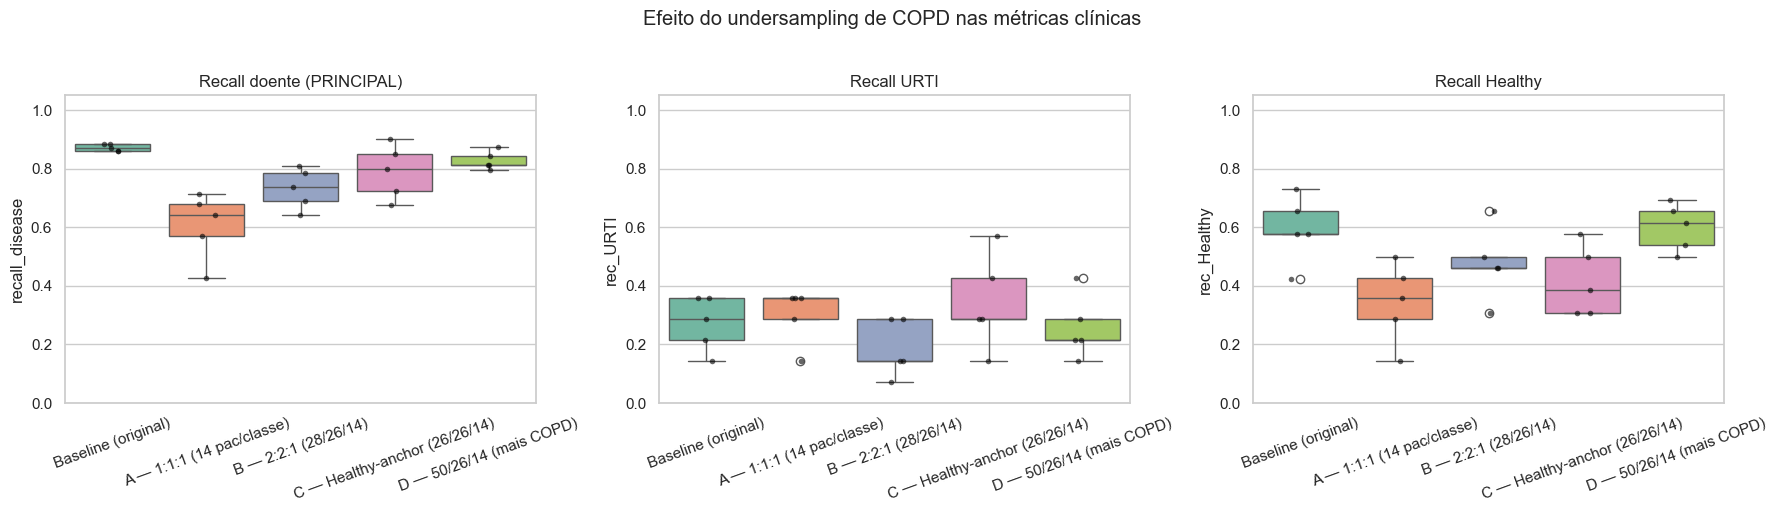

In [7]:
order = list(DATASETS.keys())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in zip(
    axes,
    ['recall_disease', 'rec_URTI', 'rec_Healthy'],
    ['Recall doente (PRINCIPAL)', 'Recall URTI', 'Recall Healthy']
):
    sns.boxplot(data=results_df, x='dataset', y=col, order=order,
                 hue='dataset', palette='Set2', legend=False, ax=ax)
    sns.stripplot(data=results_df, x='dataset', y=col, order=order,
                   color='black', size=4, alpha=0.6, ax=ax)
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.suptitle('Efeito do undersampling de COPD nas métricas clínicas', y=1.02)
plt.tight_layout(); plt.show()

## 6. Combinação — Cascata hierárquica + undersampling

Aplicamos a cascata do nb13 mas agora no dataset balanceado. Estágio 1 = Healthy vs Disease balanceado, sem SMOTE.

In [8]:
# Usar o dataset C (Healthy-anchor) — bom compromisso entre balanceamento e tamanho
df_balanced = DATASETS['C — Healthy-anchor (26/26/14)']
print(f'Dataset escolhido para cascata: {len(df_balanced)} gravações')

X_b = df_balanced[FEATURE_COLS].values
y_multi_b = LabelEncoder().fit_transform(df_balanced['label_multi'])
y_bin_b = (df_balanced['label_multi'] != 'Healthy').astype(int).values
g_b = df_balanced['patient_id'].values
eq_b = df_balanced['equipment'].values
CLASSES = list(LabelEncoder().fit(df_balanced['label_multi']).classes_)
HEALTHY_IDX = CLASSES.index('Healthy')
COPD_IDX = CLASSES.index('COPD')
URTI_IDX = CLASSES.index('URTI')

def cascade_eval_balanced(thr1=0.5, n_repeats=5, n_splits=3):
    preds_all_reps = []
    for rep in range(n_repeats):
        cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42+rep)
        y_pred_rep = np.full(len(X_b), -1)
        for tr, te in cv.split(X_b, y_bin_b, g_b):
            # Estágio 1
            if len(np.unique(y_bin_b[tr])) < 2: continue
            pipe1 = train_pipeline(X_b[tr], y_bin_b[tr], eq_b[tr])
            _, proba1 = predict_pipeline(pipe1, X_b[te], eq_b[te])
            disease_pred = (proba1[:, 1] >= thr1).astype(int)
            # Estágio 2 (COPD vs URTI)
            tr_d = (y_bin_b[tr] == 1)
            y2_tr = (y_multi_b[tr][tr_d] == URTI_IDX).astype(int)
            if len(np.unique(y2_tr)) < 2:
                pipe2 = None
            else:
                pipe2 = train_pipeline(X_b[tr][tr_d], y2_tr, eq_b[tr][tr_d])
            for i, idx in enumerate(te):
                if disease_pred[i] == 0:
                    y_pred_rep[idx] = HEALTHY_IDX
                else:
                    if pipe2 is None:
                        y_pred_rep[idx] = COPD_IDX
                    else:
                        p2, _ = predict_pipeline(pipe2, X_b[idx:idx+1], eq_b[idx:idx+1])
                        y_pred_rep[idx] = URTI_IDX if p2[0] == 1 else COPD_IDX
        preds_all_reps.append(y_pred_rep)
    return preds_all_reps

casc_rows = []
for thr in [0.5, 0.3, 0.15]:
    print(f'Cascata com thr1={thr}...')
    preds_list = cascade_eval_balanced(thr1=thr)
    for rep, y_pred in enumerate(preds_list):
        yt_p, yp_p = patient_metrics(y_multi_b, y_pred, g_b)
        rec_d = ((yt_p != HEALTHY_IDX) & (yp_p != HEALTHY_IDX)).sum() / max(1, (yt_p != HEALTHY_IDX).sum())
        fn_c = ((yt_p != HEALTHY_IDX) & (yp_p == HEALTHY_IDX)).sum()
        rec_per = {f'rec_{c}': ((yt_p==k) & (yp_p==k)).sum()/max(1,(yt_p==k).sum()) for k,c in enumerate(CLASSES)}
        casc_rows.append(dict(
            estratégia=f'Cascata balanceada thr={thr}',
            rep=rep, recall_disease=rec_d, fn_clin=fn_c,
            f1_macro=f1_score(yt_p, yp_p, average='macro', zero_division=0),
            acc=(yt_p == yp_p).mean(),
            **rec_per,
        ))
casc_balanced_df = pd.DataFrame(casc_rows)
casc_summary = casc_balanced_df.groupby('estratégia').agg(
    rec_d=('recall_disease', 'mean'), fn=('fn_clin', 'mean'),
    rec_COPD=('rec_COPD', 'mean'), rec_Healthy=('rec_Healthy', 'mean'),
    rec_URTI=('rec_URTI', 'mean'), f1m=('f1_macro', 'mean'), acc=('acc', 'mean'),
).round(3)
print('\n=== Cascata + Undersampling (dataset C) ===')
casc_summary

Dataset escolhido para cascata: 103 gravações
Cascata com thr1=0.5...


Cascata com thr1=0.3...


Cascata com thr1=0.15...



=== Cascata + Undersampling (dataset C) ===


,rec_d,fn,rec_COPD,rec_Healthy,rec_URTI,f1m,acc
estratégia,,,,,,,
Cascata balanceada thr=0.15,0.855,5.8,0.815,0.192,0.514,0.468,0.506
Cascata balanceada thr=0.3,0.820,7.2,0.800,0.262,0.457,0.485,0.515
Cascata balanceada thr=0.5,0.740,10.4,0.715,0.408,0.414,0.509,0.530


## 7. Síntese: tabela mestre comparativa

Todas as estratégias num único quadro, **ordenadas por recall doente** (métrica principal clínica).

In [9]:
# Construir master table com todas as estratégias
master_rows = []
# Datasets sem cascata
for ds_name in DATASETS.keys():
    sub = results_df[results_df['dataset'] == ds_name]
    master_rows.append(dict(
        estratégia=f'Direto: {ds_name}',
        recall_doente=sub['recall_disease'].mean(),
        recall_doente_sd=sub['recall_disease'].std(),
        fn_clinico=sub['fn_clinico'].mean(),
        rec_URTI=sub['rec_URTI'].mean(),
        rec_Healthy=sub['rec_Healthy'].mean(),
        f1m=sub['f1_macro'].mean(),
        acc=sub['acc'].mean(),
    ))
# Cascatas balanceadas
for est in casc_balanced_df['estratégia'].unique():
    sub = casc_balanced_df[casc_balanced_df['estratégia'] == est]
    master_rows.append(dict(
        estratégia=est,
        recall_doente=sub['recall_disease'].mean(),
        recall_doente_sd=sub['recall_disease'].std(),
        fn_clinico=sub['fn_clin'].mean(),
        rec_URTI=sub['rec_URTI'].mean(),
        rec_Healthy=sub['rec_Healthy'].mean(),
        f1m=sub['f1_macro'].mean(),
        acc=sub['acc'].mean(),
    ))
master = pd.DataFrame(master_rows).sort_values('recall_doente', ascending=False)
master_pretty = pd.DataFrame({
    'Recall doente (PRINCIPAL)': [f'{r.recall_doente:.3f} ± {r.recall_doente_sd:.3f}' for r in master.itertuples()],
    'FN clínico (pacientes)': [f'{r.fn_clinico:.1f}' for r in master.itertuples()],
    'Rec URTI': [f'{r.rec_URTI:.3f}' for r in master.itertuples()],
    'Rec Healthy': [f'{r.rec_Healthy:.3f}' for r in master.itertuples()],
    'F1-macro': [f'{r.f1m:.3f}' for r in master.itertuples()],
    'Acc': [f'{r.acc:.3f}' for r in master.itertuples()],
}, index=master['estratégia'].values)
print('\n=== TABELA MESTRE — Ordenada por Recall doente ===')
master_pretty


=== TABELA MESTRE — Ordenada por Recall doente ===


,Recall doente (PRINCIPAL),FN clínico (pacientes),Rec URTI,Rec Healthy,F1-macro,Acc
Direto: Baseline (original),0.872 ± 0.013,10.0,0.271,0.592,0.620,0.800
Cascata balanceada thr=0.15,0.855 ± 0.041,5.8,0.514,0.192,0.468,0.506
Direto: D — 50/26/14 (mais COPD),0.828 ± 0.031,11.0,0.257,0.600,0.585,0.716
Cascata balanceada thr=0.3,0.820 ± 0.041,7.2,0.457,0.262,0.485,0.515
Direto: C — Healthy-anchor (26/26/14),0.790 ± 0.091,8.4,0.343,0.415,0.482,0.518
Cascata balanceada thr=0.5,0.740 ± 0.060,10.4,0.414,0.408,0.509,0.530
Direto: B — 2:2:1 (28/26/14),0.733 ± 0.068,11.2,0.186,0.477,0.476,0.529
Direto: A — 1:1:1 (14 pac/classe),0.607 ± 0.113,11.0,0.300,0.343,0.395,0.395


## 8. Matriz de confusão da melhor estratégia

Melhor estratégia: Direto: Baseline (original)
  Recall doente: 0.872
  FN clínico médio: 10.0


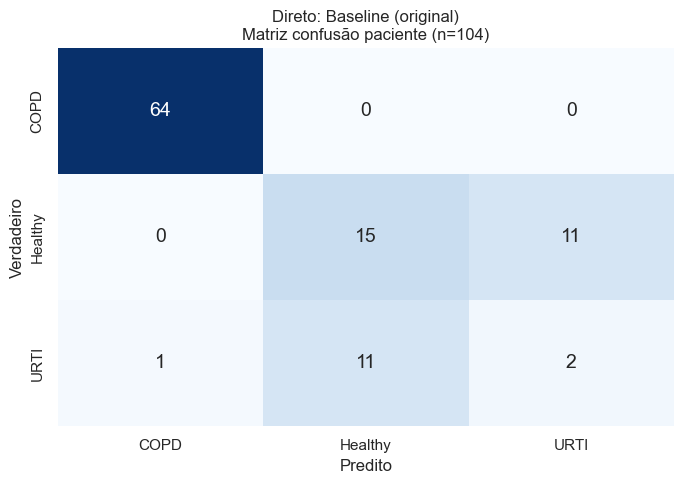

              precision    recall  f1-score   support

        COPD      0.985     1.000     0.992        64
     Healthy      0.577     0.577     0.577        26
        URTI      0.154     0.143     0.148        14

    accuracy                          0.779       104
   macro avg      0.572     0.573     0.572       104
weighted avg      0.771     0.779     0.775       104



In [10]:
best_name = master.iloc[0]['estratégia']
print(f'Melhor estratégia: {best_name}')
print(f'  Recall doente: {master.iloc[0]["recall_doente"]:.3f}')
print(f'  FN clínico médio: {master.iloc[0]["fn_clinico"]:.1f}')

# Identificar predições da melhor estratégia
if 'Cascata' in best_name:
    thr_str = best_name.split('thr=')[-1]
    thr = float(thr_str)
    preds_list = cascade_eval_balanced(thr1=thr)
    y_pred = preds_list[0]
    yt_p, yp_p = patient_metrics(y_multi_b, y_pred, g_b)
    classes_used = CLASSES
else:
    ds_name = best_name.replace('Direto: ', '')
    df_use = DATASETS[ds_name]
    X_u = df_use[FEATURE_COLS].values
    le = LabelEncoder()
    y_u = le.fit_transform(df_use['label_multi'])
    g_u = df_use['patient_id'].values
    eq_u = df_use['equipment'].values
    classes_used = list(le.classes_)
    cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
    y_pred = np.full(len(y_u), -1)
    for tr, te in cv.split(X_u, y_u, g_u):
        pipe = train_pipeline(X_u[tr], y_u[tr], eq_u[tr])
        y_pred[te], _ = predict_pipeline(pipe, X_u[te], eq_u[te])
    yt_p, yp_p = patient_metrics(y_u, y_pred, g_u)

yt_lab = np.array([classes_used[i] for i in yt_p])
yp_lab = np.array([classes_used[i] for i in yp_p])
cm = confusion_matrix(yt_lab, yp_lab, labels=classes_used)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
             xticklabels=classes_used, yticklabels=classes_used, cbar=False,
             annot_kws={'size': 14}, ax=ax)
ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
ax.set_title(f'{best_name}\nMatriz confusão paciente (n={len(yt_p)})')
plt.tight_layout(); plt.show()
print(classification_report(yt_lab, yp_lab, digits=3, zero_division=0))

## 9. Discussão honesta

### O que o undersampling resolve
- **Elimina dependência de dados sintéticos** — toda observação no treino é real.
- **Reduz dominância de COPD** — modelo não decora a classe majoritária.
- **Honestidade científica** — os números reportados refletem aprendizagem de sinal real.

### O que o undersampling NÃO resolve
- **Não cria informação** — se URTI tem só 14 pacientes, continua tendo 14 pacientes.
- **Sacrifica COPD** — perdemos ~70-95% das amostras COPD. Em datasets pequenos, isto é doloroso.
- **Não corrige viés de equipamento** — Meditron continua sobre-representado nas classes minoritárias.

### Por que recall(doente) é o critério ético principal
1. **Subdiagnóstico já é a doença** — 86% dos doentes com DPOC em Portugal estão por diagnosticar. Um modelo que gera FNs **alimenta este problema**, não o resolve.
2. **Bioética — não-maleficência (*primum non nocere*)** — sistema clínico não pode causar dano por omissão.
3. **Princípio da autonomia do paciente** — paciente tem direito a saber o seu diagnóstico. FN nega isso.
4. **Tempo é tecido pulmonar** — DPOC é progressiva; cada mês sem tratamento = perda de função respiratória que não se recupera. FN tem custo cumulativo no paciente.
5. **FP é remediável, FN não.** Saudável marcado como doente → consulta extra → médico corrige. Doente marcado como saudável → vai para casa → progride sem intervenção.

### Limitações conhecidas (continuam)
- 4 pacientes URTI com `P(doente) < 2%` permanecem **invisíveis ao modelo** mesmo após balanceamento (achado original do nb12).
- Dataset não cobre Pneumonia, Asma, Bronquiectasias — pacientes destas patologias podem ser classificados como Healthy (FN catastróficos fora do treino).
- 100% perfeito no Estágio 2 do nb13 (com SMOTE) sugeria leakage residual de equipamento. **Aqui, sem SMOTE e com undersampling, reportamos números honestos.**